In [26]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler, StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [27]:
file_path = "../data/weatherstats_fortmcmurray_hourly.csv"

df = pd.read_csv(file_path)

print("Kích thước dữ liệu ban đầu:", df.shape)
display(df.head())
print("Tên các cột:", df.columns.tolist())

Kích thước dữ liệu ban đầu: (50000, 22)


,date_time_local,unixtime,pressure_station,pressure_sea,wind_dir,wind_dir_10s,wind_speed,wind_gust,relative_humidity,dew_point,temperature,windchill,humidex,visibility,health_index,cloud_cover_4,cloud_cover_8,cloud_cover_10,solar_radiation,max_air_temp_pst1hr,min_air_temp_pst1hr,precipitation
0,2026-10-12 09:00:00 MDT,1791817200,96.97,101.53,SSE,16.0,11.0,NaN,79.0,-1.3,2.0,NaN,NaN,16100.0,NaN,0.0,NaN,NaN,NaN,2.0,0.3,NaN
1,2026-10-12 08:00:00 MDT,1791813600,97.07,101.64,S,18.0,9.0,NaN,83.0,-2.0,0.5,NaN,NaN,16100.0,1.4,2.0,NaN,NaN,NaN,0.9,0.4,NaN
2,2026-10-12 07:00:00 MDT,1791810000,97.10,101.67,SSE,16.0,11.0,NaN,84.0,-2.0,0.4,NaN,NaN,16100.0,1.4,0.0,NaN,NaN,NaN,2.0,0.4,NaN
3,2026-10-12 06:00:00 MDT,1791806400,97.20,101.76,S,18.0,13.0,28.0,77.0,-1.5,2.1,NaN,NaN,16100.0,1.3,1.0,NaN,NaN,NaN,3.2,2.1,NaN
4,2026-10-12 05:00:00 MDT,1791802800,97.27,101.83,SSW,20.0,13.0,NaN,74.0,-1.1,3.0,NaN,NaN,16100.0,1.3,4.0,NaN,NaN,NaN,3.0,2.0,NaN


Tên các cột: ['date_time_local', 'unixtime', 'pressure_station', 'pressure_sea', 'wind_dir', 'wind_dir_10s', 'wind_speed', 'wind_gust', 'relative_humidity', 'dew_point', 'temperature', 'windchill', 'humidex', 'visibility', 'health_index', 'cloud_cover_4', 'cloud_cover_8', 'cloud_cover_10', 'solar_radiation', 'max_air_temp_pst1hr', 'min_air_temp_pst1hr', 'precipitation']


In [28]:
print("Số lượng giá trị thiếu theo từng cột:")
print(df.isnull().sum())
print("\nTổng số giá trị thiếu trong toàn bộ tập dữ liệu:", df.isnull().sum().sum())

Số lượng giá trị thiếu theo từng cột:
date_time_local            0
unixtime                   0
pressure_station           1
pressure_sea               1
wind_dir                  15
wind_dir_10s              10
wind_speed                25
wind_gust              42244
relative_humidity          3
dew_point                  4
temperature                4
windchill              30907
humidex                47245
visibility                59
health_index             947
cloud_cover_4            465
cloud_cover_8          50000
cloud_cover_10         50000
solar_radiation        50000
max_air_temp_pst1hr        2
min_air_temp_pst1hr        2
precipitation             32
dtype: int64

Tổng số giá trị thiếu trong toàn bộ tập dữ liệu: 271966


In [29]:
# 1. Loại bỏ các cột có tỷ lệ thiếu quá cao (> 50% số dòng không có dữ liệu)
# Các cột: cloud_cover_8, cloud_cover_10, solar_radiation (100% NaN),
# humidex (94.5% NaN), wind_gust (84.5% NaN), windchill (61.8% NaN)
threshold = 0.5 * len(df)
df_clean = df.dropna(axis=1, thresh=threshold).copy()

# 2. Xóa các dòng còn chứa giá trị thiếu (dropna với how="any")
df_clean = df_clean.dropna(axis=0, how="any").copy()

print("Số dòng ban đầu:", len(df))
print("Số dòng sau khi làm sạch:", len(df_clean))
print("Số dòng đã loại bỏ:", len(df) - len(df_clean))
print("Kích thước dữ liệu sau khi xử lý missing:", df_clean.shape)
print("Số giá trị thiếu còn lại:", df_clean.isnull().sum().sum())

display(df_clean.head())

Số dòng ban đầu: 50000
Số dòng sau khi làm sạch: 48522
Số dòng đã loại bỏ: 1478
Kích thước dữ liệu sau khi xử lý missing: (48522, 16)
Số giá trị thiếu còn lại: 0


,date_time_local,unixtime,pressure_station,pressure_sea,wind_dir,wind_dir_10s,wind_speed,relative_humidity,dew_point,temperature,visibility,health_index,cloud_cover_4,max_air_temp_pst1hr,min_air_temp_pst1hr,precipitation
29,2026-10-11 04:00:00 MDT,1791712800,98.28,102.90,ESE,12.0,5.0,90.0,-2.4,-0.9,16100.0,1.0,4.0,-0.7,-1.2,0.0
30,2026-10-11 03:00:00 MDT,1791709200,98.26,102.88,ESE,12.0,4.0,89.0,-2.4,-0.8,16100.0,1.2,4.0,0.1,-1.2,0.0
31,2026-10-11 02:00:00 MDT,1791705600,98.24,102.86,ESE,12.0,5.0,81.0,-2.7,0.2,16100.0,1.2,4.0,0.4,-1.2,0.0
32,2026-10-11 01:00:00 MDT,1791702000,98.24,102.86,ENE,6.0,4.0,83.0,-2.2,0.3,16100.0,1.3,4.0,1.6,0.3,0.0
33,2026-10-11 00:00:00 MDT,1791698400,98.22,102.84,N,36.0,5.0,80.0,-2.1,1.0,16100.0,1.4,3.0,2.6,0.9,0.0


In [30]:
numeric_cols = df_clean.select_dtypes(include=np.number).columns
categorical_cols = df_clean.select_dtypes(exclude=np.number).columns

# Bảng thống kê các biến định lượng: Mean, Median, Standard Deviation, Mode
stats_numeric = pd.DataFrame({
    "Mean": df_clean[numeric_cols].mean(),
    "Median": df_clean[numeric_cols].median(),
    "Standard Deviation": df_clean[numeric_cols].std(),
    "Mode": df_clean[numeric_cols].mode().iloc[0]
})

print("--- Thống kê các cột số (Numerical columns) ---")
display(stats_numeric)

# Mode cho các biến định tính / thời gian
stats_categorical = pd.DataFrame({
    "Mode": df_clean[categorical_cols].mode().iloc[0]
})

print("--- Mode của các cột phân loại / thời gian (Categorical columns) ---")
display(stats_categorical)

--- Thống kê các cột số (Numerical columns) ---


,Mean,Median,Standard Deviation,Mode
unixtime,1.701389e+09,1.701182e+09,5.198052e+07,1.611821e+09
pressure_station,9.695936e+01,9.693000e+01,8.771032e-01,9.716000e+01
pressure_sea,1.015125e+02,1.014500e+02,9.764824e-01,1.016100e+02
wind_dir_10s,2.037235e+01,2.200000e+01,9.844394e+00,1.100000e+01
wind_speed,1.262741e+01,1.100000e+01,7.102541e+00,9.000000e+00
relative_humidity,6.851123e+01,7.200000e+01,1.920504e+01,7.600000e+01
dew_point,-3.440196e+00,-1.800000e+00,1.299261e+01,1.050000e+01
temperature,2.589092e+00,4.800000e+00,1.480741e+01,1.340000e+01
visibility,1.483597e+04,1.610000e+04,3.470378e+03,1.610000e+04
health_index,2.328253e+00,2.000000e+00,1.556637e+00,2.000000e+00


--- Mode của các cột phân loại / thời gian (Categorical columns) ---


,Mode
date_time_local,2021-01-28 01:00:00 MST
wind_dir,E


In [31]:
# Không tính outlier cho unixtime vì đây là timestamp
feature_numeric_cols = [col for col in numeric_cols if col != "unixtime"]

outlier_counts = {}

for col in feature_numeric_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_counts[col] = (
        (df_clean[col] < lower) |
        (df_clean[col] > upper)
    ).sum()

display(pd.DataFrame.from_dict(
    outlier_counts,
    orient="index",
    columns=["Outlier Count"]
))

,Outlier Count
pressure_station,968
pressure_sea,1256
wind_dir_10s,0
wind_speed,858
relative_humidity,6
dew_point,104
temperature,13
visibility,6999
health_index,3441
cloud_cover_4,0


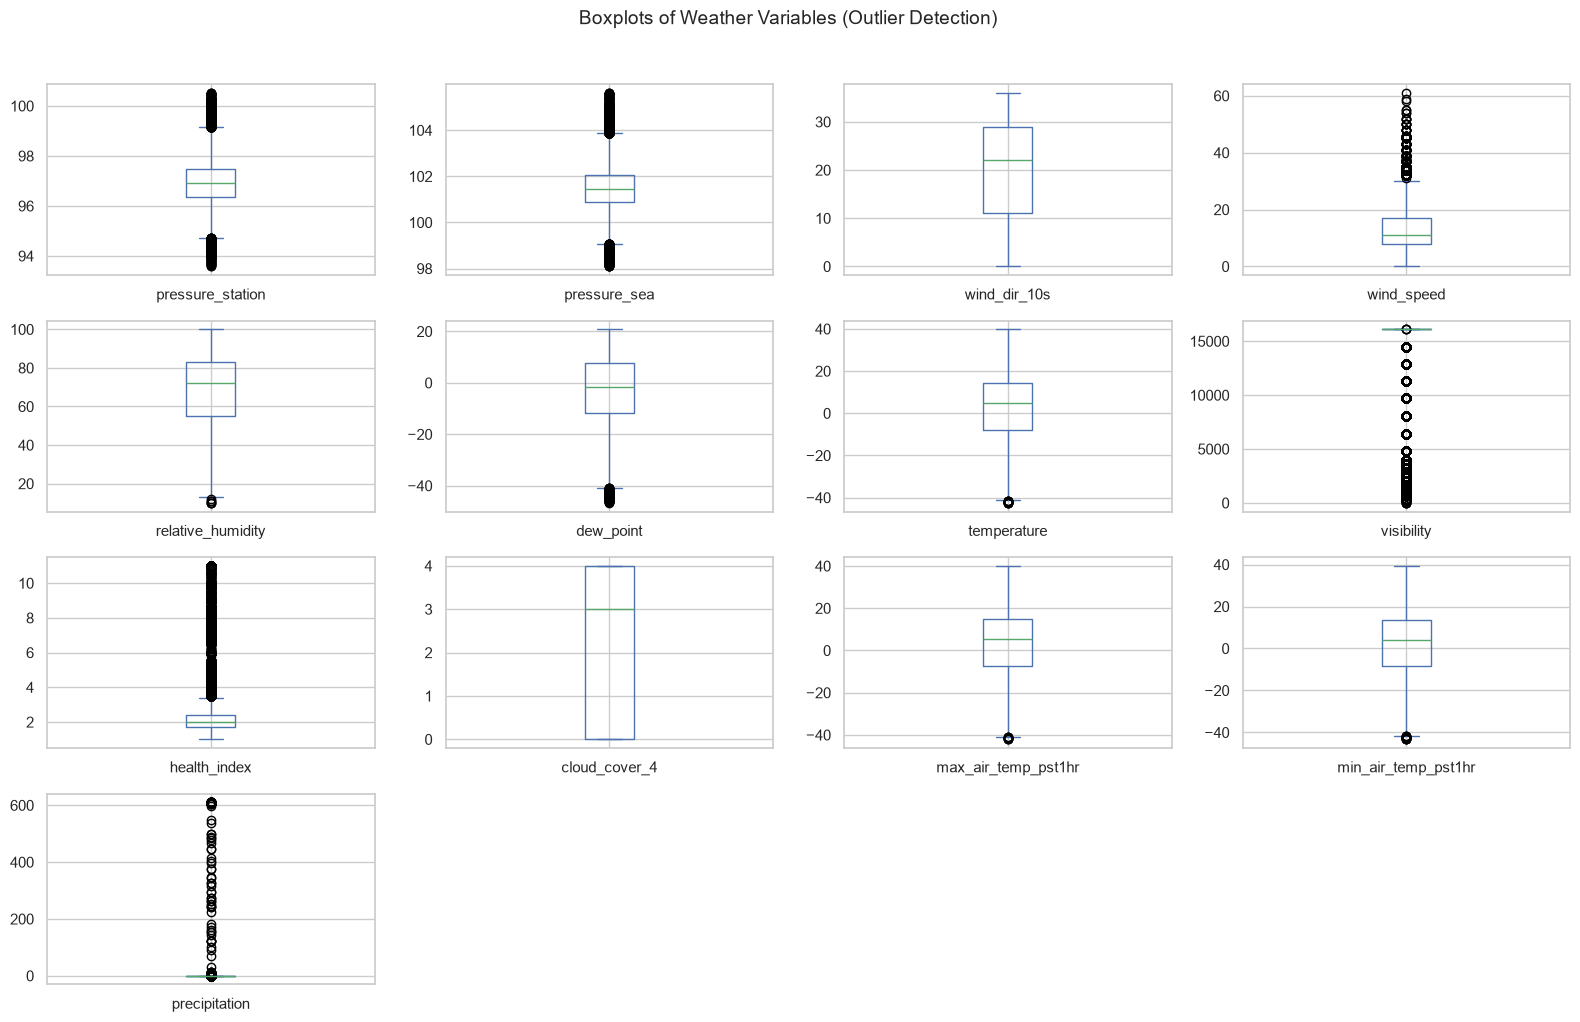

In [32]:
df_clean[feature_numeric_cols].plot(
    kind="box",
    subplots=True,
    layout=(-1, 4),
    figsize=(16, 10),
    sharex=False,
    sharey=False
)

plt.suptitle("Boxplots of Weather Variables (Outlier Detection)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [33]:
# Lọc ngoại lai trên các biến khí tượng liên tục chính
# (Tránh lọc cứng nhắc trên precipitation vì mưa là sự kiện hiếm nhưng hợp lệ)
continuous_weather_cols = [
    "pressure_station", "pressure_sea", "wind_speed",
    "relative_humidity", "dew_point", "temperature",
    "max_air_temp_pst1hr", "min_air_temp_pst1hr"
]

outlier_mask = pd.Series(False, index=df_clean.index)

for col in continuous_weather_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_mask |= (
        (df_clean[col] < lower) |
        (df_clean[col] > upper)
    )

df_no_outliers = df_clean.loc[~outlier_mask].copy()

print("Trước khi loại ngoại lai:", len(df_clean))
print("Sau khi loại ngoại lai:", len(df_no_outliers))
print("Số dòng ngoại lai bị loại bỏ:", len(df_clean) - len(df_no_outliers))

Trước khi loại ngoại lai: 48522
Sau khi loại ngoại lai: 46318
Số dòng ngoại lai bị loại bỏ: 2204


In [34]:
# Chọn các cột số cần scale (bỏ unixtime vì là mốc thời gian)
scale_cols = [col for col in df_no_outliers.select_dtypes(include=np.number).columns if col != "unixtime"]

minmax_scaler = MinMaxScaler()
df_minmax = df_no_outliers.copy()
df_minmax[scale_cols] = minmax_scaler.fit_transform(df_no_outliers[scale_cols])

print("Dữ liệu sau khi chuẩn hóa Min-Max (Min-Max Normalization):")
display(df_minmax.head())

Dữ liệu sau khi chuẩn hóa Min-Max (Min-Max Normalization):


,date_time_local,unixtime,pressure_station,pressure_sea,wind_dir,wind_dir_10s,wind_speed,relative_humidity,dew_point,temperature,visibility,health_index,cloud_cover_4,max_air_temp_pst1hr,min_air_temp_pst1hr,precipitation
29,2026-10-11 04:00:00 MDT,1791712800,0.805869,0.798319,ESE,0.333333,0.166667,0.885057,0.623987,0.472114,1.0,0.00,1.00,0.469441,0.493134,0.0
30,2026-10-11 03:00:00 MDT,1791709200,0.801354,0.794118,ESE,0.333333,0.133333,0.873563,0.623987,0.473411,1.0,0.02,1.00,0.479844,0.493134,0.0
31,2026-10-11 02:00:00 MDT,1791705600,0.796840,0.789916,ESE,0.333333,0.166667,0.781609,0.619125,0.486381,1.0,0.02,1.00,0.483745,0.493134,0.0
32,2026-10-11 01:00:00 MDT,1791702000,0.796840,0.789916,ENE,0.166667,0.133333,0.804598,0.627229,0.487678,1.0,0.03,1.00,0.499350,0.511860,0.0
33,2026-10-11 00:00:00 MDT,1791698400,0.792325,0.785714,N,1.000000,0.166667,0.770115,0.628849,0.496757,1.0,0.04,0.75,0.512354,0.519351,0.0


In [35]:
zscore_scaler = StandardScaler()
df_zscore = df_no_outliers.copy()
df_zscore[scale_cols] = zscore_scaler.fit_transform(df_no_outliers[scale_cols])

print("Dữ liệu sau khi chuẩn hóa Z-score (Z-Score Normalization):")
display(df_zscore.head())

Dữ liệu sau khi chuẩn hóa Z-score (Z-Score Normalization):


,date_time_local,unixtime,pressure_station,pressure_sea,wind_dir,wind_dir_10s,wind_speed,relative_humidity,dew_point,temperature,visibility,health_index,cloud_cover_4,max_air_temp_pst1hr,min_air_temp_pst1hr,precipitation
29,2026-10-11 04:00:00 MDT,1791712800,1.717465,1.638182,ESE,-0.833127,-1.129062,1.107754,0.034770,-0.284550,0.360789,-0.846418,0.971306,-0.312339,-0.260482,-0.057561
30,2026-10-11 03:00:00 MDT,1791709200,1.692018,1.615178,ESE,-0.833127,-1.284607,1.055761,0.034770,-0.277566,0.360789,-0.719939,0.971306,-0.256881,-0.260482,-0.057561
31,2026-10-11 02:00:00 MDT,1791705600,1.666571,1.592173,ESE,-0.833127,-1.129062,0.639817,0.010796,-0.207723,0.360789,-0.719939,0.971306,-0.236084,-0.260482,-0.057561
32,2026-10-11 01:00:00 MDT,1791702000,1.666571,1.592173,ENE,-1.441486,-1.284607,0.743803,0.050753,-0.200739,0.360789,-0.656699,0.971306,-0.152896,-0.154891,-0.057561
33,2026-10-11 00:00:00 MDT,1791698400,1.641123,1.569169,N,1.600307,-1.129062,0.587824,0.058744,-0.151849,0.360789,-0.593459,0.418833,-0.083574,-0.112655,-0.057561


In [36]:
print("Danh sách các cột trong tập dữ liệu sau xử lý ngoại lai:")
print(df_no_outliers.columns.tolist())

Danh sách các cột trong tập dữ liệu sau xử lý ngoại lai:
['date_time_local', 'unixtime', 'pressure_station', 'pressure_sea', 'wind_dir', 'wind_dir_10s', 'wind_speed', 'relative_humidity', 'dew_point', 'temperature', 'visibility', 'health_index', 'cloud_cover_4', 'max_air_temp_pst1hr', 'min_air_temp_pst1hr', 'precipitation']


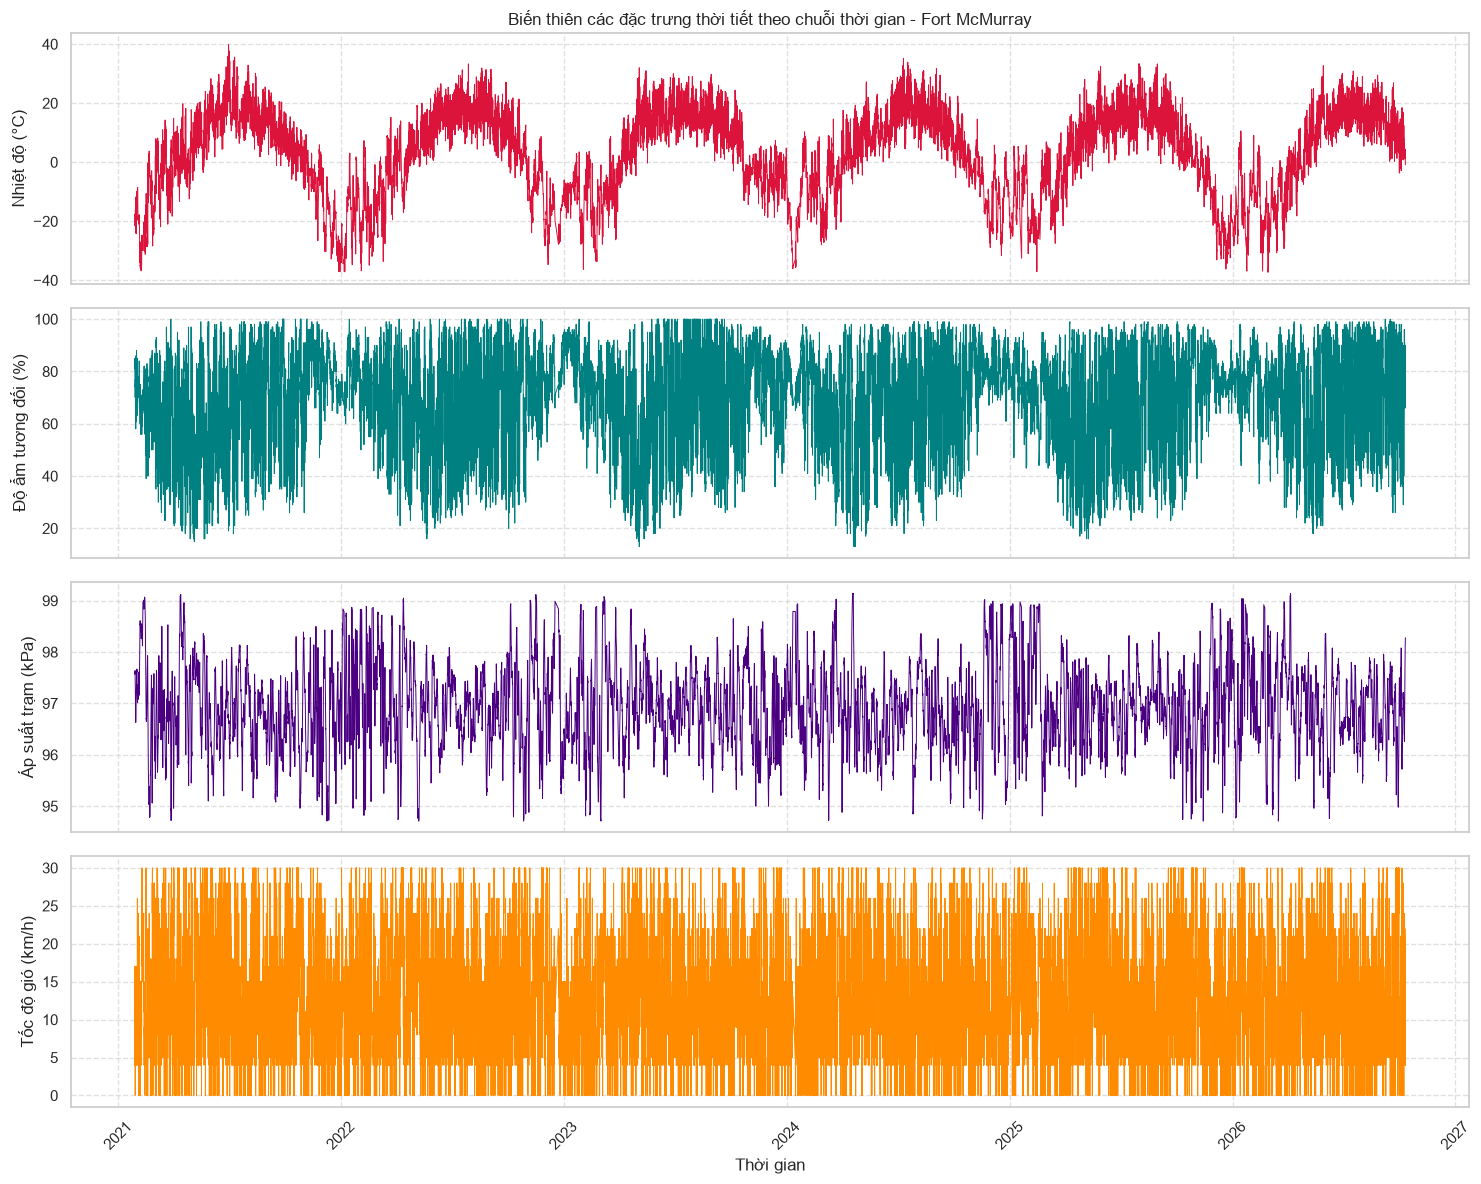

In [37]:
# Trực quan hóa nhiều đặc trưng thời tiết theo chuỗi thời gian (Time Series)
df_plot = df_no_outliers.copy()

# Chuyển cột thời gian sang kiểu datetime (bỏ nhãn múi giờ MDT để parse chuẩn xác)
df_plot["date_time_local"] = pd.to_datetime(
    df_plot["date_time_local"].str.replace(r"\s+[A-Z]{3,4}$", "", regex=True),
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

df_plot = df_plot.dropna(subset=["date_time_local"]).sort_values("date_time_local")

# Vẽ 4 đặc trưng thời tiết chính theo thời gian
fig, axes = plt.subplots(4, 1, figsize=(15, 12), sharex=True)

axes[0].plot(df_plot["date_time_local"], df_plot["temperature"], color="crimson", linewidth=0.7)
axes[0].set_ylabel("Nhiệt độ (°C)")
axes[0].set_title("Biến thiên các đặc trưng thời tiết theo chuỗi thời gian - Fort McMurray")
axes[0].grid(True, linestyle="--", alpha=0.6)

axes[1].plot(df_plot["date_time_local"], df_plot["relative_humidity"], color="teal", linewidth=0.7)
axes[1].set_ylabel("Độ ẩm tương đối (%)")
axes[1].grid(True, linestyle="--", alpha=0.6)

axes[2].plot(df_plot["date_time_local"], df_plot["pressure_station"], color="indigo", linewidth=0.7)
axes[2].set_ylabel("Áp suất trạm (kPa)")
axes[2].grid(True, linestyle="--", alpha=0.6)

axes[3].plot(df_plot["date_time_local"], df_plot["wind_speed"], color="darkorange", linewidth=0.7)
axes[3].set_ylabel("Tốc độ gió (km/h)")
axes[3].set_xlabel("Thời gian")
axes[3].grid(True, linestyle="--", alpha=0.6)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

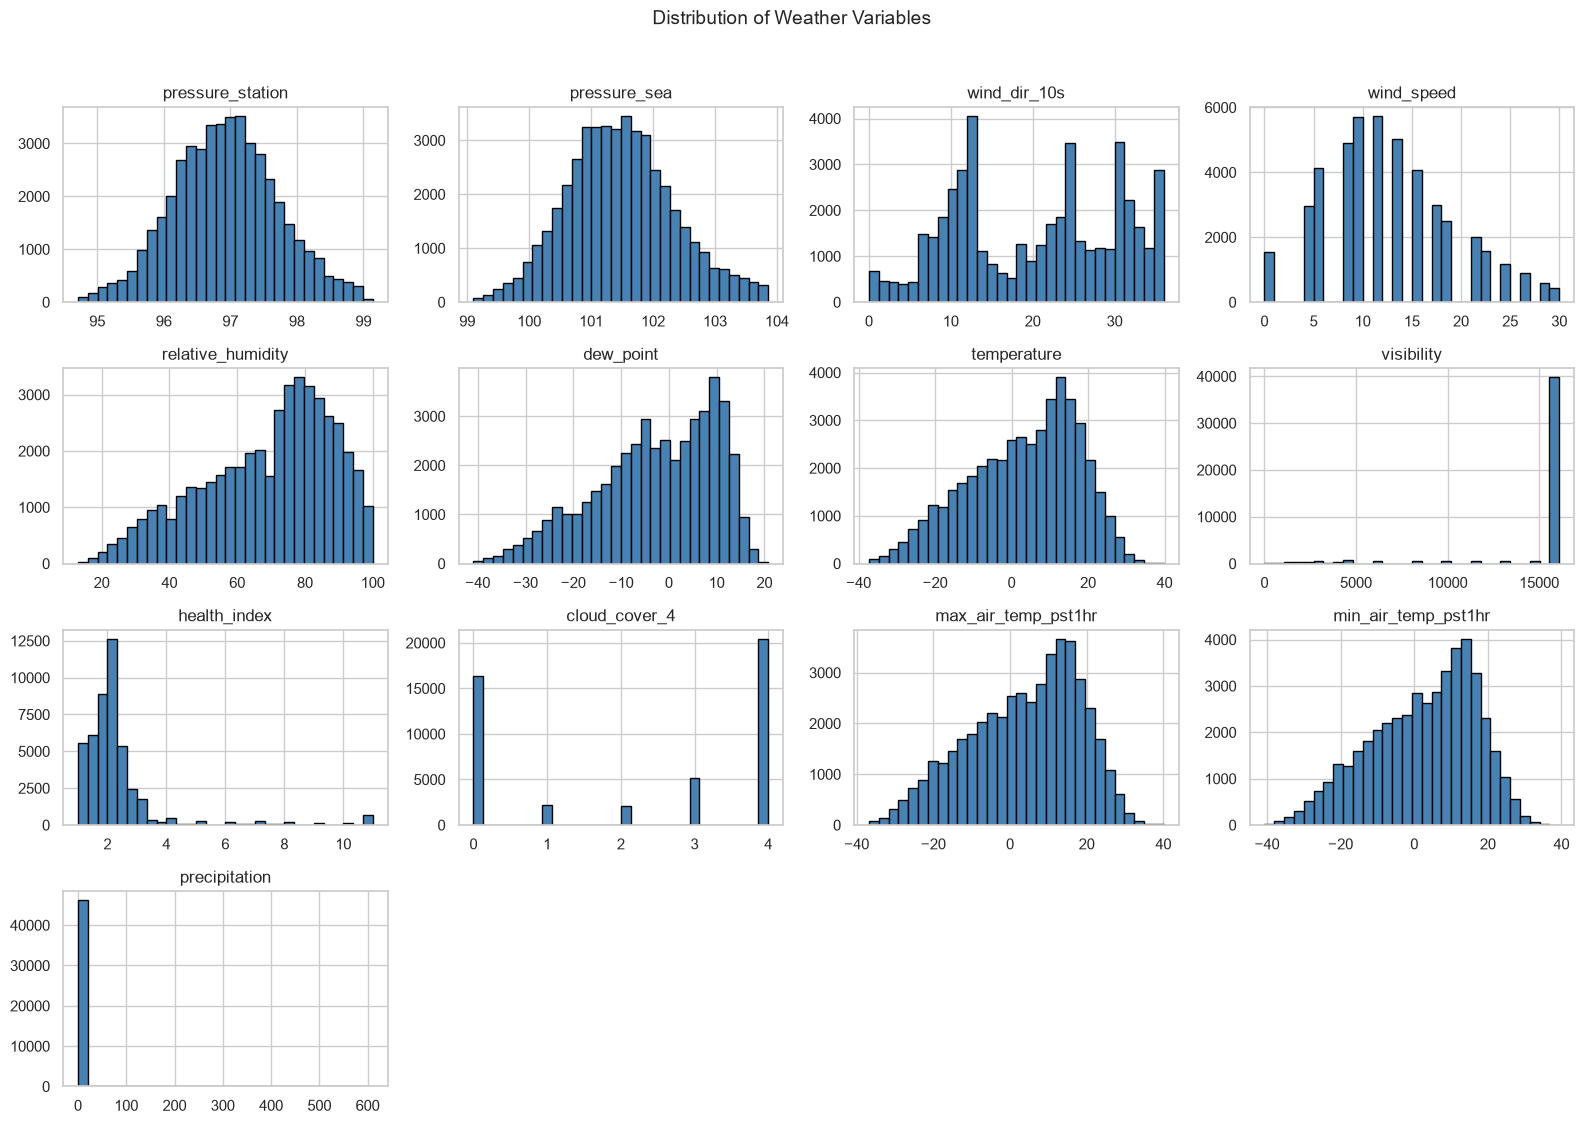

In [38]:
# Phân phối tần suất của các biến thời tiết (Histogram)
plot_numeric_cols = [col for col in df_no_outliers.select_dtypes(include=np.number).columns if col != "unixtime"]

df_no_outliers[plot_numeric_cols].hist(
    figsize=(16, 11),
    bins=30,
    edgecolor="black",
    color="steelblue"
)

plt.suptitle("Distribution of Weather Variables", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

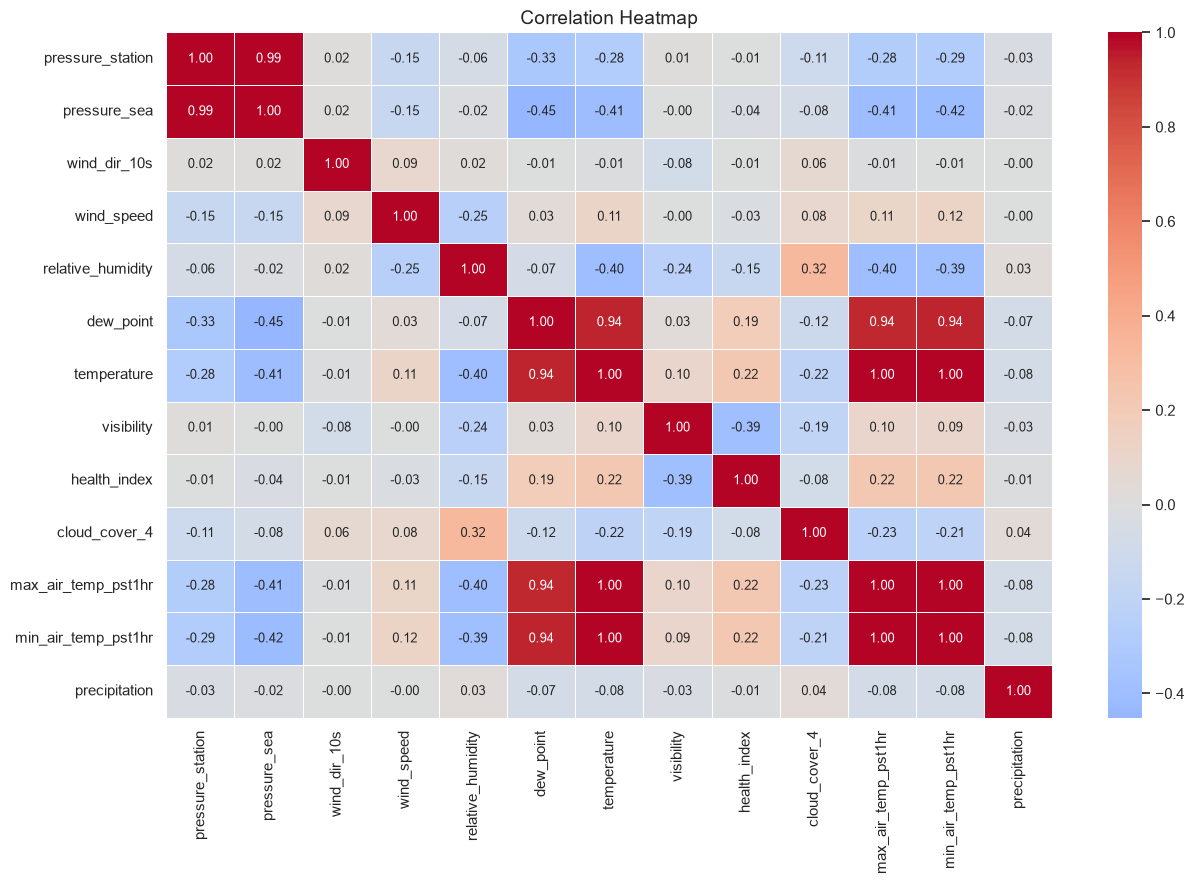

In [39]:
# Ma trận tương quan giữa các đặc trưng (Correlation Heatmap)
correlation = df_no_outliers[plot_numeric_cols].corr()

plt.figure(figsize=(13, 9))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0,
    linewidths=0.5,
    annot_kws={"size": 9}
)

plt.title("Correlation Heatmap", fontsize=14)
plt.tight_layout()
plt.show()

In [40]:
import os

os.makedirs("../output", exist_ok=True)

df_clean.to_csv("../output/climate_clean.csv", index=False)
df_no_outliers.to_csv("../output/climate_no_outliers.csv", index=False)
df_minmax.to_csv("../output/climate_minmax.csv", index=False)
df_zscore.to_csv("../output/climate_zscore.csv", index=False)
stats_numeric.to_csv("../output/statistics.csv")

print("Đã lưu thành công tất cả kết quả vào thư mục output:")
print("- ../output/climate_clean.csv")
print("- ../output/climate_no_outliers.csv")
print("- ../output/climate_minmax.csv")
print("- ../output/climate_zscore.csv")
print("- ../output/statistics.csv")

Đã lưu thành công tất cả kết quả vào thư mục output:
- ../output/climate_clean.csv
- ../output/climate_no_outliers.csv
- ../output/climate_minmax.csv
- ../output/climate_zscore.csv
- ../output/statistics.csv
